In [1]:
from pathlib import Path
import subprocess
import sys
import json
import hashlib

import torch

REPO_URL = "https://github.com/MRdrissi/industrial-defect-ai.git"
BRANCH = "feature/us-03-04-cae-hazelnut"

REPO_DIR = Path("/kaggle/working/industrial-defect-ai")

if not (REPO_DIR / ".git").is_dir():
    subprocess.run(
        [
            "git", "clone",
            "--branch", BRANCH,
            "--single-branch",
            REPO_URL,
            str(REPO_DIR)
        ],
        check=True
    )

COMMIT_SHA = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    text=True
).strip()

sys.path.insert(0, str(REPO_DIR))

print("Code version:", COMMIT_SHA)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "Activer un GPU dans Kaggle."

DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))


Cloning into '/kaggle/working/industrial-defect-ai'...


Code version: 742b8346e664b4efc50410b3707bdb2db6908c1f
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
import csv

experiment_path = (
        REPO_DIR / "experiments/configs/cae_hazelnut.json"
)

with experiment_path.open(encoding="utf-8") as f:
    experiment = json.load(f)

architecture_path = (
        REPO_DIR / experiment["architecture_config"]
)

with architecture_path.open(encoding="utf-8") as f:
    architecture = json.load(f)["config"]

manifest_path = (
        REPO_DIR / experiment["dataset"]["manifest"]
)

manifest_sha256 = hashlib.sha256(
    manifest_path.read_bytes()
).hexdigest()

EXPECTED_MANIFEST_SHA = (
    "8f0e0d5b5bb767cd2d2e6f8a0ab10f65a959a97a38bb14bc5d9aae1d30c81fb6"
)

assert manifest_sha256 == EXPECTED_MANIFEST_SHA

with manifest_path.open(
        encoding="utf-8", newline=""
) as f:
    rows = list(csv.DictReader(f))

train_rows = [
    row for row in rows
    if row["category"] == "hazelnut"
       and row["split"] == "train"
]

val_rows = [
    row for row in rows
    if row["category"] == "hazelnut"
       and row["split"] == "val"
]

assert len(train_rows) == 313
assert len(val_rows) == 78

assert all(
    row["label"] == "0" and row["defect_type"] == "good"
    for row in train_rows + val_rows
)

train_paths = {row["image_path"] for row in train_rows}
val_paths = {row["image_path"] for row in val_rows}

assert train_paths.isdisjoint(val_paths)

print("Experiment:", experiment["experiment_name"])
print("Manifest SHA256:", manifest_sha256)
print("Train:", len(train_rows))
print("Validation:", len(val_rows))
print("Train/Val disjoint:", True)
print("Dataset protocol: OK")


Experiment: cae_hazelnut_baseline_v1
Manifest SHA256: 8f0e0d5b5bb767cd2d2e6f8a0ab10f65a959a97a38bb14bc5d9aae1d30c81fb6
Train: 313
Validation: 78
Train/Val disjoint: True
Dataset protocol: OK


In [3]:
from src.data.mvtec_dataset import MVTecDataset
from src.data.transforms import MVTecTransform
from src.data.dataloaders import create_dataloader

# Identifier la racine réelle du dataset attaché
good_dirs = list(
    Path("/kaggle/input").rglob("hazelnut/train/good")
)

assert len(good_dirs) == 1, (
    f"Racine Hazelnut ambiguë ou absente : {good_dirs}"
)

DATASET_ROOT = good_dirs[0].parents[2]

print("MVTec root:", DATASET_ROOT)

transform = MVTecTransform(
    size=tuple(architecture["image_size"]),
    profile="cae"
)

train_dataset = MVTecDataset(
    dataset_root=DATASET_ROOT,
    manifest_path=manifest_path,
    category="hazelnut",
    split="train",
    transform=transform
)

val_dataset = MVTecDataset(
    dataset_root=DATASET_ROOT,
    manifest_path=manifest_path,
    category="hazelnut",
    split="val",
    transform=transform
)

assert len(train_dataset) == 313
assert len(val_dataset) == 78

sample = train_dataset[0]

assert sample["image"].shape == (3, 256, 256)
assert sample["image"].dtype == torch.float32
assert 0 <= sample["image"].min().item()
assert sample["image"].max().item() <= 1
assert sample["label"] == 0

print("Sample shape:", tuple(sample["image"].shape))
print("Sample range:", (
    sample["image"].min().item(),
    sample["image"].max().item()
))
print("Hazelnut datasets: OK")


MVTec root: /kaggle/input/datasets/ipythonx/mvtec-ad
Sample shape: (3, 256, 256)
Sample range: (0.10588235408067703, 0.8196078538894653)
Hazelnut datasets: OK


In [4]:
from src.models.convolutional_autoencoder import (
    CAEConfig,
    ConvolutionalAutoencoder
)

training = experiment["training"]

config = CAEConfig(
    input_channels=architecture["input_channels"],
    image_size=tuple(architecture["image_size"]),
    encoder_channels=tuple(
        architecture["encoder_channels"]
    ),
    latent_channels=architecture["latent_channels"],
    seed=training["seed"]
)

torch.manual_seed(config.seed)
torch.cuda.manual_seed_all(config.seed)

model = ConvolutionalAutoencoder(config).to(DEVICE)

parameter_count = sum(
    p.numel() for p in model.parameters()
)

assert parameter_count == 855619

model.eval()

with torch.inference_mode():
    image = sample["image"].unsqueeze(0).to(DEVICE)
    reconstruction = model(image)

assert reconstruction.shape == image.shape
assert torch.isfinite(reconstruction).all().item()

print("Parameters:", parameter_count)
print("Input:", tuple(image.shape))
print("Output:", tuple(reconstruction.shape))
print("CAE GPU forward: OK")


Parameters: 855619
Input: (1, 3, 256, 256)
Output: (1, 3, 256, 256)
CAE GPU forward: OK


In [5]:

import random
import numpy as np

from src.data.dataloaders import create_dataloader

# Configuration de reproductibilité
seed = training["seed"]

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Chargement selon le manifeste
train_loader = create_dataloader(
    train_dataset,
    batch_size=training["batch_size"],
    num_workers=training["num_workers"],
    seed=seed,
)

val_loader = create_dataloader(
    val_dataset,
    batch_size=training["batch_size"],
    num_workers=training["num_workers"],
    seed=seed,
)

assert len(train_loader) == 20
assert len(val_loader) == 5

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", training["batch_size"])
print("Workers:", training["num_workers"])
print("Seed:", seed)
print("DataLoaders: OK")


Train batches: 20
Validation batches: 5
Batch size: 16
Workers: 2
Seed: 42
DataLoaders: OK


In [11]:

from torch import nn

def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    model.train(is_training)

    total_loss = 0.0
    total_images = 0

    for batch in loader:
        images = batch["image"].to(DEVICE)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            reconstructions = model(images)
            loss = criterion(reconstructions, images)

            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_images += batch_size

    if total_images == 0:
        raise RuntimeError("DataLoader vide")

    return total_loss / total_images


In [12]:

# Modèle temporaire pour le smoke test
torch.manual_seed(config.seed)
torch.cuda.manual_seed_all(config.seed)

test_model = ConvolutionalAutoencoder(
    config
).to(DEVICE)

criterion = nn.MSELoss()

test_optimizer = torch.optim.Adam(
    test_model.parameters(),
    lr=training["learning_rate"]
)

# Une seule époque Train
train_mse = run_epoch(
    model=test_model,
    loader=train_loader,
    criterion=criterion,
    optimizer=test_optimizer,
)

# Une seule époque Validation
val_mse = run_epoch(
    model=test_model,
    loader=val_loader,
    criterion=criterion,
)

assert np.isfinite(train_mse)
assert np.isfinite(val_mse)

print(f"Train MSE: {train_mse:.8f}")
print(f"Validation MSE: {val_mse:.8f}")
print("One-epoch GPU smoke test: OK")


Train MSE: 0.06026585
Validation MSE: 0.02139997
One-epoch GPU smoke test: OK


In [13]:

import csv
import json
import random
import sys
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch

# Chaque run possède son propre répertoire.
RUN_ID = "hazelnut-baseline-001"
OUTPUT_DIR = Path("/kaggle/working/cae/hazelnut") / RUN_ID

# Ne jamais écraser silencieusement une expérience.
if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()):
    raise FileExistsError(
        f"Ce run existe déjà : {OUTPUT_DIR}. "
        "Choisir un nouvel identifiant."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / "best_model.pt"
HISTORY_PATH = OUTPUT_DIR / "history.csv"
METADATA_PATH = OUTPUT_DIR / "run_info.json"

# Réinitialiser les générateurs après le smoke test.
seed = training["seed"]

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Recréer les DataLoaders pour notre vrai run.
official_train_loader = create_dataloader(
    train_dataset,
    batch_size=training["batch_size"],
    num_workers=training["num_workers"],
    seed=seed,
)

official_val_loader = create_dataloader(
    val_dataset,
    batch_size=training["batch_size"],
    num_workers=training["num_workers"],
    seed=seed,
)

# Nouveau modèle : aucun poids du smoke test.
train_model = ConvolutionalAutoencoder(config).to(DEVICE)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    train_model.parameters(),
    lr=training["learning_rate"],
)

stopping = training["early_stopping"]
max_epochs = training["max_epochs"]

best_val = float("inf")
best_epoch = None

# Référence séparée pour la patience.
significant_best = float("inf")
epochs_without_improvement = 0

history = []
stop_reason = "max_epochs"

metadata = {
    "run_id": RUN_ID,
    "experiment": experiment,
    "architecture": asdict(config),
    "git_commit": COMMIT_SHA,
    "manifest_sha256": manifest_sha256,
    "dataset": {
        "category": "hazelnut",
        "train_images": len(train_dataset),
        "validation_images": len(val_dataset),
    },
    "environment": {
        "python": sys.version,
        "pytorch": torch.__version__,
        "gpu": torch.cuda.get_device_name(0),
    },
    "status": "running",
}

for epoch in range(1, max_epochs + 1):

    train_mse = run_epoch(
        train_model,
        official_train_loader,
        criterion,
        optimizer,
    )

    val_mse = run_epoch(
        train_model,
        official_val_loader,
        criterion,
    )

    if not np.isfinite(train_mse) or not np.isfinite(val_mse):
        raise RuntimeError(
            f"Loss non finie à l'époque {epoch}"
        )

    history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
    })

    # Sauvegarder chaque nouveau minimum strict.
    if val_mse < best_val:
        best_val = val_mse
        best_epoch = epoch

        torch.save(
            {
                "model_state_dict": train_model.state_dict(),
                "model_config": asdict(config),
                "epoch": best_epoch,
                "best_val_mse": best_val,
                "git_commit": COMMIT_SHA,
                "manifest_sha256": manifest_sha256,
            },
            CHECKPOINT_PATH,
        )

    # Early Stopping : amélioration significative.
    if val_mse < significant_best - stopping["min_delta"]:
        significant_best = val_mse
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Historique enregistré à chaque époque.
    with HISTORY_PATH.open(
        "w", newline="", encoding="utf-8"
    ) as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["epoch", "train_mse", "val_mse"],
        )
        writer.writeheader()
        writer.writerows(history)

    metadata.update({
        "epochs_completed": epoch,
        "best_epoch": best_epoch,
        "best_val_mse": best_val,
        "last_train_mse": train_mse,
        "last_val_mse": val_mse,
    })

    with METADATA_PATH.open("w", encoding="utf-8") as f:
        json.dump(metadata, f, indent=2)

    print(
        f"Epoch {epoch:03d}/{max_epochs} | "
        f"Train: {train_mse:.8f} | "
        f"Val: {val_mse:.8f} | "
        f"Best: {best_val:.8f} (E{best_epoch})"
    )

    if (
        stopping["enabled"]
        and epochs_without_improvement >= stopping["patience"]
    ):
        stop_reason = "early_stopping"
        print(f"Early stopping at epoch {epoch}")
        break

metadata["status"] = "completed"
metadata["stop_reason"] = stop_reason

with METADATA_PATH.open("w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("\nTraining completed")
print("Epochs:", len(history))
print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val)
print("Stop reason:", stop_reason)
print("Checkpoint:", CHECKPOINT_PATH)


Epoch 001/150 | Train: 0.06026585 | Val: 0.02139997 | Best: 0.02139997 (E1)
Epoch 002/150 | Train: 0.01013331 | Val: 0.00654043 | Best: 0.00654043 (E2)
Epoch 003/150 | Train: 0.00529351 | Val: 0.00456264 | Best: 0.00456264 (E3)
Epoch 004/150 | Train: 0.00426447 | Val: 0.00398797 | Best: 0.00398797 (E4)
Epoch 005/150 | Train: 0.00380416 | Val: 0.00371789 | Best: 0.00371789 (E5)
Epoch 006/150 | Train: 0.00353035 | Val: 0.00337955 | Best: 0.00337955 (E6)
Epoch 007/150 | Train: 0.00292420 | Val: 0.00211080 | Best: 0.00211080 (E7)
Epoch 008/150 | Train: 0.00150271 | Val: 0.00122663 | Best: 0.00122663 (E8)
Epoch 009/150 | Train: 0.00097774 | Val: 0.00083367 | Best: 0.00083367 (E9)
Epoch 010/150 | Train: 0.00080458 | Val: 0.00072636 | Best: 0.00072636 (E10)
Epoch 011/150 | Train: 0.00068573 | Val: 0.00066419 | Best: 0.00066419 (E11)
Epoch 012/150 | Train: 0.00063747 | Val: 0.00061073 | Best: 0.00061073 (E12)
Epoch 013/150 | Train: 0.00062111 | Val: 0.00062763 | Best: 0.00061073 (E12)
Epoch 01

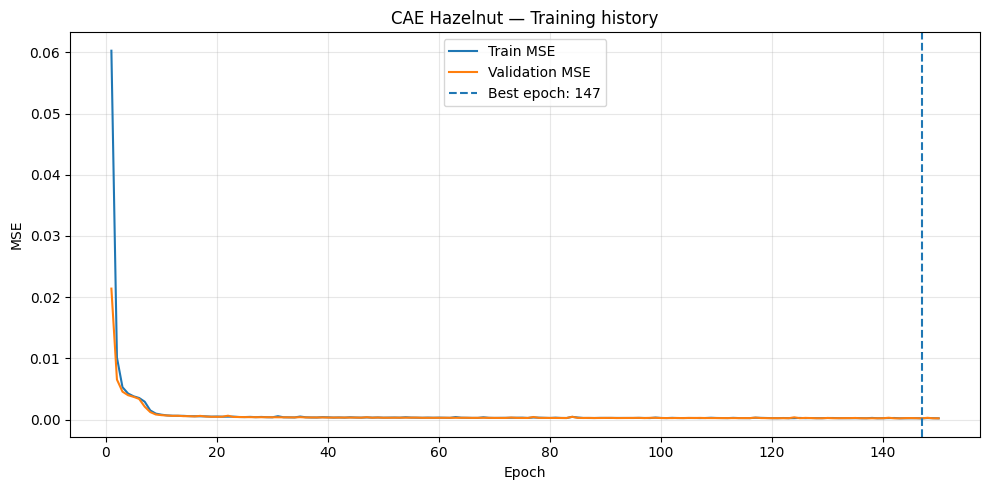

History: /kaggle/working/cae/hazelnut/hazelnut-baseline-001/history.csv
Curve: /kaggle/working/cae/hazelnut/hazelnut-baseline-001/loss_curves.png
Metadata: /kaggle/working/cae/hazelnut/hazelnut-baseline-001/run_info.json
Checkpoint: /kaggle/working/cae/hazelnut/hazelnut-baseline-001/best_model.pt


In [14]:

import matplotlib.pyplot as plt

epochs = [row["epoch"] for row in history]
train_losses = [row["train_mse"] for row in history]
val_losses = [row["val_mse"] for row in history]

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_losses, label="Train MSE")
plt.plot(epochs, val_losses, label="Validation MSE")

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("CAE Hazelnut — Training history")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

CURVE_PATH = OUTPUT_DIR / "loss_curves.png"
plt.savefig(CURVE_PATH, dpi=150)

plt.show()

print("History:", HISTORY_PATH)
print("Curve:", CURVE_PATH)
print("Metadata:", METADATA_PATH)
print("Checkpoint:", CHECKPOINT_PATH)


In [15]:

from pathlib import Path
import csv
import hashlib
import shutil
import torch
from IPython.display import display, FileLink

run_dir = Path(
    "/kaggle/working/cae/hazelnut/hazelnut-baseline-001"
)

# 1. Vérifier les quatre artefacts
required = [
    "best_model.pt",
    "history.csv",
    "loss_curves.png",
    "run_info.json",
]

for name in required:
    assert (run_dir / name).is_file(), f"Missing: {name}"

# 2. Vérifier l'historique
with (run_dir / "history.csv").open(
    encoding="utf-8", newline=""
) as file:
    rows = list(csv.DictReader(file))

assert len(rows) == 150

best_row = min(
    rows, key=lambda row: float(row["val_mse"])
)

# 3. Examiner le checkpoint sans modifier ses poids
checkpoint = torch.load(
    run_dir / "best_model.pt",
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["epoch"] == int(best_row["epoch"])
assert abs(
    checkpoint["best_val_mse"]
    - float(best_row["val_mse"])
) < 1e-10

print("Epochs:", len(rows))
print("Best epoch:", checkpoint["epoch"])
print("Best val MSE:", checkpoint["best_val_mse"])
print("Git commit:", checkpoint["git_commit"])
print("Checkpoint consistency: OK")

# 4. Créer une archive téléchargeable
archive = shutil.make_archive(
    str(run_dir),
    "zip",
    root_dir=run_dir.parent,
    base_dir=run_dir.name,
)

digest = hashlib.sha256(
    Path(archive).read_bytes()
).hexdigest()

print("Archive:", archive)
print("Archive SHA256:", digest)

display(FileLink(archive))


Epochs: 150
Best epoch: 147
Best val MSE: 0.00020595180364743544
Git commit: 742b8346e664b4efc50410b3707bdb2db6908c1f
Checkpoint consistency: OK
Archive: /kaggle/working/cae/hazelnut/hazelnut-baseline-001.zip
Archive SHA256: 6a278b214ad83ccc9b326c3952465a105bf071d8b426ef6452cbf401df4fcdc0


/kaggle/working/cae/hazelnut/hazelnut-baseline-001.zip